# 06 — Modèle de sentiment des avis clients

**Question métier (service client)** : que disent les clients dans leurs avis ?

**Objectif** : repérer automatiquement les avis **négatifs** pour les traiter en priorité, et comprendre de quoi ils parlent.

Le code est dans `src/shoppulse/sentiment.py` ; le pipeline `pipelines/train_flow.py` entraîne les modèles et écrit `docs/sentiment_report.md`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve

from shoppulse.sentiment import (
    NEURAL,
    TARGET,
    TFIDF,
    ReviewDataset,
    SentimentExperiment,
    TextNormalizer,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

## 1. Stratégie de langue

Les avis sont en **portugais**. Trois options étaient possibles :

| Option | Coût | Délai | Performance attendue | Données clients | Poids dans l'API |
|---|---|---|---|---|---|
| **Entraînement direct en portugais** | nul | minutes | bonne si assez d'exemples | restent chez nous | léger (quelques Mo) |
| Traduction automatique puis modèle | payant (≈ 41 000 avis) | heures | perte de nuances, erreurs de traduction | **envoyées à un service externe** (RGPD) | léger |
| Modèle multilingue pré-entraîné (BERT) | GPU conseillé | heures | la meilleure en théorie | restent chez nous | lourd (≈ 1 Go) |

**Choix : entraînement direct.** Nous avons plus de 37 000 avis étiquetés par leur note, ce qui suffit pour apprendre le vocabulaire des clients ; c'est gratuit, rapide, conforme au RGPD (aucun avis ne quitte l'infrastructure) et l'API reste légère. Les résultats (section 5) confirment que c'était suffisant.

## 2. Les données

- **Cible** : un avis est **négatif** pour une note de 1 ou 2, **positif** pour 4 ou 5. Les notes de 3, ambiguës, sont exclues de l'apprentissage et étudiées à part (section 7).
- **Texte** : titre + message, en minuscules ; on garde les accents, la négation (« não ») et les points d'exclamation.
- **Découpage temporel** : 70 % des avis les plus anciens pour apprendre, 15 % pour régler, 15 % les plus récents pour tester.

In [2]:
reviews = ReviewDataset().load()
parts = ReviewDataset.split(reviews)
summary = pd.DataFrame({
    name: {
        "avis": len(part),
        "début": part["creation_date"].min().date(),
        "fin": part["creation_date"].max().date(),
        "% négatifs": round(100 * part[TARGET].mean(), 1)
        if name != "neutral" else None,
    }
    for name, part in parts.items()
}).T
summary

,avis,début,fin,% négatifs
train,25991,2016-10-02,2018-04-21,30.5
validation,5569,2018-04-21,2018-06-27,26.9
test,5570,2018-06-27,2018-08-31,23.9
neutral,3529,2016-10-19,2018-08-31,None


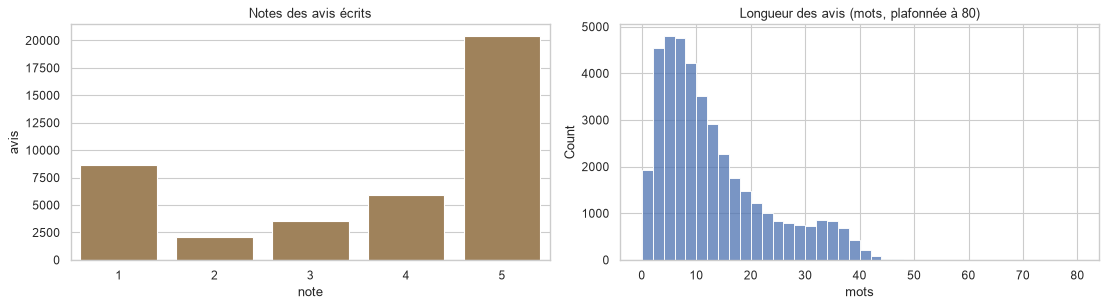

Longueur médiane : 10 mots


In [3]:
lengths = reviews["text"].map(lambda text: len(TextNormalizer.tokenize(text)))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x="score", data=reviews, color="#AA8350", ax=axes[0])
axes[0].set(title="Notes des avis écrits", xlabel="note", ylabel="avis")
sns.histplot(lengths.clip(upper=80), bins=40, ax=axes[1])
axes[1].set(title="Longueur des avis (mots, plafonnée à 80)", xlabel="mots")
plt.tight_layout()
plt.show()
print(f"Longueur médiane : {lengths.median():.0f} mots")

Les avis sont **courts** (une dizaine de mots en médiane) et les clients qui écrivent sont plus souvent mécontents : 29 % d'avis négatifs parmi les avis écrits.

## 3. Entraînement des deux modèles

- **Baseline** : TF-IDF sur les mots et les paires de mots (« não recebi ») + régression logistique avec classes équilibrées. La force de régularisation C est choisie sur la validation.
- **Réseau de neurones** (PyTorch) : chaque mot devient un vecteur appris (plongement de dimension 64), un **GRU bidirectionnel** lit l'avis dans les deux sens, puis une couche de sortie donne la probabilité que l'avis soit négatif. Perte pondérée pour le déséquilibre, *dropout* de 30 %, **arrêt anticipé** quand la PR-AUC de validation ne progresse plus pendant 3 époques.

L'expérience complète prend environ une minute et demie.

In [4]:
experiment = SentimentExperiment(reviews)
results = experiment.run()
results.tfidf_tuning.round(4)

,C,pr_auc
0,0.5,0.9354
1,1.0,0.9392
2,2.0,0.9414
3,4.0,0.9422
4,8.0,0.9430
5,16.0,0.9422
6,32.0,0.9400
7,64.0,0.9393


La PR-AUC de validation est maximale pour **C = 8**, à l'intérieur de la grille testée : le réglage n'est pas bloqué en bordure.

### Ce que la baseline a appris

In [5]:
results.top_terms.round(2)

,négatif,poids négatif,positif,poids positif
0,não,16.12,parabéns,-8.34
1,nao,9.50,só não,-8.17
2,não recomendo,8.87,lindo,-7.95
3,péssimo,7.47,amei,-7.48
4,péssima,6.82,rápido,-6.96
5,nem,6.76,obrigada,-6.60
6,não recebi,6.43,rápida,-6.39
7,ruim,6.36,perfeito,-6.10
8,adorei recebi,5.91,adorei,-5.98
9,quebrado,5.88,recomendo,-5.72


**Lecture** : les mots qui annoncent un avis négatif sont la **négation** (« não », « nem »), les problèmes de livraison (« não recebi », « aguardando », « demora »), le produit abîmé ou incomplet (« quebrado », « faltando », « inferior ») et les jugements (« péssimo », « ruim »). Côté positif : remerciements, rapidité, « antes » (livré *avant* le délai). « Só não » (« seulement, il manque… ») est positif : ce sont des clients satisfaits qui signalent un petit défaut. Ce modèle est **explicable** : on peut montrer à un conseiller pourquoi un avis est classé négatif.

## 4. Courbes d'apprentissage du réseau de neurones

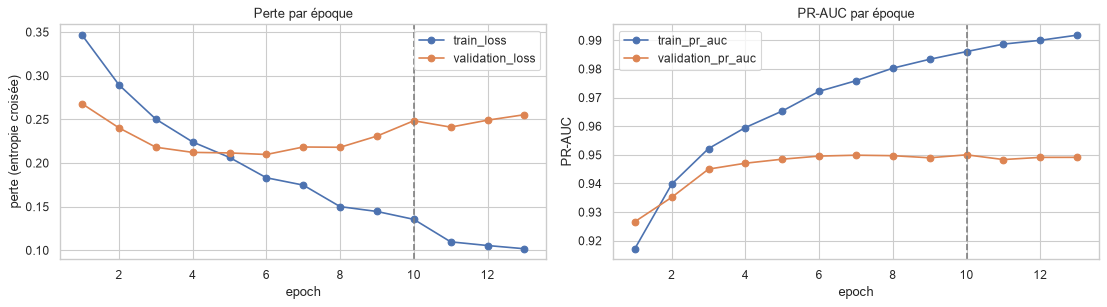

Meilleure époque (PR-AUC de validation) : 10


In [6]:
history = results.history.set_index("epoch")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
history[["train_loss", "validation_loss"]].plot(ax=axes[0], marker="o")
axes[0].set(title="Perte par époque", ylabel="perte (entropie croisée)")
history[["train_pr_auc", "validation_pr_auc"]].plot(ax=axes[1], marker="o")
best_epoch = history["validation_pr_auc"].idxmax()
for ax in axes:
    ax.axvline(best_epoch, color="grey", linestyle="--")
axes[1].set(title="PR-AUC par époque", ylabel="PR-AUC")
plt.tight_layout()
plt.show()
print(f"Meilleure époque (PR-AUC de validation) : {best_epoch}")

**Lecture** : la perte d'apprentissage baisse à chaque époque, mais la perte de validation remonte après quelques époques et la PR-AUC de validation plafonne : le réseau commence à **apprendre par cœur** les avis d'apprentissage (sur-apprentissage). L'arrêt anticipé garde les poids de la meilleure époque (ligne pointillée). La PR-AUC de validation ne gagne presque plus rien après l'époque 6, alors que la perte de validation remonte : le réseau classe toujours aussi bien mais devient **trop sûr de lui** (probabilités extrêmes), ce qui explique son seuil de décision élevé (0,82 contre 0,53 pour la baseline).

### Et avec plus ou moins de données ?

On réentraîne les deux modèles sur 10 %, 25 %, 50 % et 100 % des avis d'apprentissage.

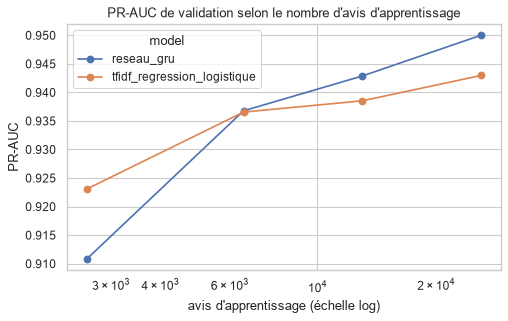

model,reseau_gru,tfidf_regression_logistique
train_reviews,,
2599,0.911,0.923
6498,0.937,0.937
12996,0.943,0.939
25991,0.950,0.943


In [7]:
curve = results.learning_curve.pivot(index="train_reviews",
                                     columns="model",
                                     values="validation_pr_auc")
ax = curve.plot(marker="o", figsize=(7, 4), logx=True)
ax.set(title="PR-AUC de validation selon le nombre d'avis d'apprentissage",
       xlabel="avis d'apprentissage (échelle log)", ylabel="PR-AUC")
plt.show()
curve.round(3)

**Lecture** : avec peu de données (2 600 avis), la baseline est meilleure ; le réseau la rattrape vers 6 500 avis puis la dépasse légèrement. Les deux courbes montent encore à 100 % : **plus d'avis amélioreraient encore les deux modèles**, le réseau en premier (un réseau de neurones a besoin de beaucoup d'exemples).

## 5. Comparaison en validation et sur le test

In [8]:
print("Seuils (F1 maximal en validation) :",
      {name: round(value, 3) for name, value in results.thresholds.items()})
display(results.validation_scores.round(3))
results.test_scores.round(3)

Seuils (F1 maximal en validation) : {'tfidf_regression_logistique': 0.531, 'reseau_gru': 0.82}


,pr_auc,roc_auc,precision_negative,recall_negative,f1_negative,macro_f1,balanced_accuracy
tfidf_regression_logistique,0.943,0.981,0.869,0.938,0.902,0.932,0.943
reseau_gru,0.950,0.983,0.886,0.936,0.911,0.938,0.946


,pr_auc,roc_auc,precision_negative,recall_negative,f1_negative,macro_f1,balanced_accuracy
tfidf_regression_logistique,0.953,0.985,0.863,0.938,0.899,0.932,0.945
reseau_gru,0.955,0.984,0.889,0.930,0.909,0.940,0.947


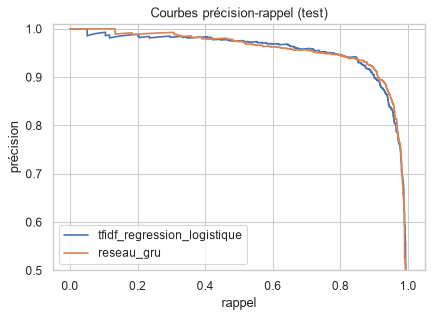

In [9]:
test = results.test_predictions
fig, ax = plt.subplots(figsize=(6, 4))
for name in (TFIDF, NEURAL):
    precision, recall, _ = precision_recall_curve(test[TARGET],
                                                  test[f"proba_{name}"])
    ax.plot(recall, precision, label=name)
ax.set(title="Courbes précision-rappel (test)", xlabel="rappel",
       ylabel="précision", ylim=(0.5, 1.01))
ax.legend()
plt.show()

**Choix du modèle** : la règle fixée **avant** l'expérience retient le réseau seulement s'il gagne au moins 0,01 de PR-AUC en validation. Il gagne moins que cela : **on retient la baseline TF-IDF**, presque aussi performante (PR-AUC ≈ 0,95 sur le test pour les deux), plus de 20 fois plus rapide à entraîner, plus légère à servir et explicable mot par mot. Sur le test, elle détecte environ **94 % des avis négatifs**, et 86 % des avis qu'elle signale sont bien négatifs.

In [10]:
best = results.best_model
threshold = results.thresholds[best]
test["prediction"] = (test[f"proba_{best}"] >= threshold).astype(int)
pd.crosstab(test[TARGET].map({0: "positif", 1: "négatif"}),
            test["prediction"].map({0: "positif", 1: "négatif"}),
            rownames=["note du client"], colnames=["prédiction"],
            margins=True)

prédiction,négatif,positif,All
note du client,,,
négatif,1250,83,1333
positif,199,4038,4237
All,1449,4121,5570


## 6. Analyse d'erreurs

In [11]:
test["error"] = test["prediction"] != test[TARGET]
test["words"] = test["text"].map(lambda text: len(TextNormalizer.tokenize(text)))
test["length"] = pd.cut(test["words"], [0, 3, 10, 30, 1000],
                        labels=["1-3 mots", "4-10", "11-30", "plus de 30"])
neural_wrong = (
    (test[f"proba_{NEURAL}"] >= results.thresholds[NEURAL])
    != test[TARGET]
)
by_length = test.groupby("length", observed=True).agg(
    avis=("error", "size"),
    erreurs_baseline=("error", "mean"),
)
by_length["erreurs_reseau"] = neural_wrong.groupby(
    test["length"], observed=True
).mean()
(100 * by_length[["erreurs_baseline", "erreurs_reseau"]]).round(1).join(
    by_length["avis"]
)

,erreurs_baseline,erreurs_reseau,avis
length,,,
1-3 mots,2.9,2.5,689
4-10,2.9,2.4,2212
11-30,6.3,6.1,2205
plus de 30,12.4,9.2,459


In [12]:
both = (test["error"] & neural_wrong).mean()
print(f"Erreurs de la baseline : {100 * test['error'].mean():.1f} % ; "
      f"du réseau : {100 * neural_wrong.mean():.1f} % ; "
      f"des deux à la fois : {100 * both:.1f} %")

Erreurs de la baseline : 5.1 % ; du réseau : 4.5 % ; des deux à la fois : 3.4 %


### Les erreurs les plus franches

In [13]:
columns = ["score", "text", f"proba_{best}"]
missed = test[(test[TARGET] == 1) & (test["prediction"] == 0)]
display(missed.nsmallest(8, f"proba_{best}")[columns].round(3))
false_alarms = test[(test[TARGET] == 0) & (test["prediction"] == 1)]
false_alarms.nlargest(8, f"proba_{best}")[columns].round(3)

,score,text,proba_tfidf_regression_logistique
2780,1,"recomendo a loja produto de boa qualidade, entrega dentro do prazo",0.002
3210,2,entrega rapida bom e rapido na entrega,0.005
2540,2,"recomendo óculos lindo, chegou em perfeito estado. mas não foi entregue dentro do prazo.",0.008
519,2,boa compra produto bom,0.009
2028,2,muito rapido gostei muito,0.011
3863,2,***** produto bom minha filha amou,0.012
3616,2,"infelizmente,trava muito! no quesito entrega vocês estão de parabéns. chegou muito antes do previsto. pena que o tab...",0.021
3513,1,boa loja razuavel,0.022


,score,text,proba_tfidf_regression_logistique
4258,4,"bom. faltou a nota fiscal que não chegou com o produto ,e nao esta no email, que informa que já foi emitida ,e não r...",0.999
4257,5,péssima recebi o produto que eh falso quero meu dinheiro de volta,0.998
2661,4,solicitei a devolução porém não recebi os procedimentos... produto diferente da foto no site,0.998
2166,4,não recebi ainda,0.996
56,4,marreta muiti ruim,0.995
4005,4,"reclamação este produto veio certo, mas comprei uma coifa e quero devolver e não estou conseguindo. não estou tendo ...",0.995
2904,4,ainda nao recebi o,0.992
3671,4,"entrega incompleta bom dia, consta no site da lannister que recebi os dois produtos que comprei porém ainda falta o ...",0.990


**Ce qu'on comprend** :

1. **Bruit d'étiquette** : une partie des « erreurs » sont en réalité des erreurs du client, dans les deux sens. « Recomendo a loja, produto de boa qualidade, entrega dentro do prazo » est noté 1 ; « péssima, recebi o produto que é falso, quero meu dinheiro de volta » est noté 5 : le client s'est trompé d'échelle. Le modèle a raison, l'étiquette a tort. Exemple vu à l'entraînement : « adorei recebi antes do prazo » noté 1, qui donne à la paire de mots « adorei recebi » un poids négatif absurde (ce n'est qu'un seul avis : la régularisation faible, C = 8, lui laisse trop de poids).
2. **Avis mitigés** : « lunettes jolies, arrivées en parfait état, mais pas livrées dans les délais » noté 2, ou « bom, faltou a nota fiscal… » noté 4 : un seul score ne peut pas tout dire.
3. **Avis longs** : le taux d'erreur monte à 12 % au-delà de 30 mots, contre 3 % pour les avis courts ; ce sont souvent des avis mitigés qui racontent plusieurs choses. Le réseau GRU, qui lit l'ordre des mots, s'en sort mieux sur ces avis (9 %) : c'est là que se joue son petit avantage.
4. Les deux modèles se trompent **souvent sur les mêmes avis** : ce sont les cas difficiles (ou mal étiquetés), pas un défaut propre à la baseline.

## 7. Et les avis notés 3 ?

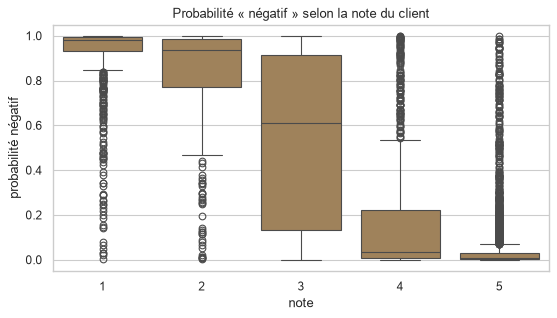

score
1    0.98
2    0.94
3    0.61
4    0.04
5    0.01
Name: proba_tfidf_regression_logistique, dtype: float64

In [14]:
neutral = results.neutral_predictions
scored = pd.concat([test[["score", f"proba_{best}"]],
                    neutral[["score", f"proba_{best}"]]])
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=scored, x="score", y=f"proba_{best}", color="#AA8350",
            ax=ax)
ax.set(title="Probabilité « négatif » selon la note du client",
       xlabel="note", ylabel="probabilité négatif")
plt.show()
scored.groupby("score")[f"proba_{best}"].median().round(2)

**Lecture** : le modèle n'a jamais vu de note 3 et pourtant il les place **entre** les avis négatifs et positifs (probabilité médiane de 0,61, contre 0,94 à 0,98 pour les notes 1-2 et 0,01 à 0,04 pour les notes 4-5) : il a appris une vraie gradation du ton, pas seulement deux catégories. Les notes de 3 penchent plutôt du côté négatif : ce sont souvent des clients déçus mais polis.

## 8. Que disent les clients mécontents ?

Réponse métier pour le service client : de quoi parlent les avis négatifs ? On compte la part d'avis qui mentionnent au moins un mot de chaque thème (un avis peut toucher plusieurs thèmes).

In [15]:
THEMES = {
    "livraison (retard, non reçu)": r"entreg|prazo|cheg|receb|atras|demor|"
                                    r"correio|aguard",
    "produit abîmé ou non conforme": r"quebr|defeit|danific|errad|"
                                     r"diferente|falsific|qualidade",
    "commande incomplète": r"falt|incomplet|apenas \d|só \d|veio só",
    "vendeur et service": r"vendedor|loja|atendiment|contato|respost|"
                          r"reembols|estorn|devolu|cancel",
}
labeled = reviews[reviews[TARGET] >= 0]
themes = pd.DataFrame({
    theme: labeled.groupby(TARGET)["text"].apply(
        lambda texts, pattern=pattern: 100 * texts.str.contains(
            pattern, regex=True
        ).mean()
    )
    for theme, pattern in THEMES.items()
}).T
themes.columns = ["avis positifs (%)", "avis négatifs (%)"]
themes.round(1).sort_values("avis négatifs (%)", ascending=False)

,avis positifs (%),avis négatifs (%)
"livraison (retard, non reçu)",50.1,69.0
vendeur et service,10.4,21.5
produit abîmé ou non conforme,9.5,15.7
commande incomplète,0.7,8.7


**Lecture** : la **livraison** est le sujet n° 1 des avis négatifs (69 % : produit non reçu, retard, attente). Elle est aussi très présente dans les avis positifs (50 %, souvent pour dire « livré avant le délai ») : c'est le moment qui fait l'expérience client, en bien comme en mal. Les thèmes qui **distinguent** le plus les avis négatifs sont la **commande incomplète** (9 % contre 1 %) et le **vendeur ou le service** (22 % contre 10 % : contact, remboursement, annulation). C'est cohérent avec le notebook 02 : **réduire les retards (modèle du notebook 04) est le premier levier pour réduire les avis négatifs**, le suivi des commandes incomplètes et des réponses vendeurs le second.

## 9. Limites et recommandations

- **Usage recommandé** : trier les nouveaux avis pour que le service client réponde d'abord aux négatifs, et suivre chaque semaine la part d'avis négatifs par thème.
- **Bruit d'étiquette** : la note du client n'est pas toujours cohérente avec son texte ; un échantillon d'avis ré-étiquetés à la main donnerait une mesure plus juste et un meilleur modèle.
- **Avis mitigés** : un seul score par avis ; une analyse par thème (livraison, produit, vendeur) serait plus fine.
- **Langue** : le modèle ne connaît que le portugais du Brésil ; pour aller plus loin, affiner un modèle pré-entraîné portugais (type BERTimbau) sur ces avis.
- **Suivi** : la part d'avis négatifs varie dans le temps (31 % à l'apprentissage, 24 % sur le test) ; réentraîner régulièrement avec `pipelines/train_flow.py`.